# Лабораторная работа №1: Wikipedia

В этой части работы я исследую англоязычные технические статьи Wikipedia. В выборке используются категории Computer science, Engineering, Mathematics, Physics, Chemistry и Biology.

## 1. Получение примеров

Для загрузки я использую официальный [MediaWiki API](https://en.wikipedia.org/w/api.php). Сырой документ представляет собой JSON-объект со служебными полями страницы и текстом статьи в поле `extract`. Полный `extract` API возвращает только для одной страницы за запрос, поэтому статьи загружаются последовательно. В выборку попадают непустые статьи размером не менее 200 слов. Примеры сохраняются в каталоге проекта `data/wikipedia_sample.json`.

In [1]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
import requests

API_URL = 'https://en.wikipedia.org/w/api.php'
CATEGORIES = ['Computer science', 'Engineering', 'Mathematics', 'Physics', 'Chemistry', 'Biology']
SAMPLE_SIZE = 30
MIN_WORDS = 200
DATA_DIR = Path('..') / 'data'
SAMPLE_FILE = DATA_DIR / 'wikipedia_sample.json'
DATA_DIR.mkdir(exist_ok=True)

session = requests.Session()
session.headers['User-Agent'] = 'MAI-IR-course-project/1.0 (educational corpus analysis)'

In [2]:
def download_wikipedia_sample():
    candidates_by_category = {}
    for category in CATEGORIES:
        response = session.get(API_URL, params={
            'action': 'query', 'format': 'json', 'formatversion': 2,
            'list': 'categorymembers', 'cmtitle': f'Category:{category}',
            'cmnamespace': 0, 'cmtype': 'page', 'cmlimit': 30,
        }, timeout=30)
        response.raise_for_status()
        candidates_by_category[category] = response.json()['query']['categorymembers']

    candidates = []
    seen_page_ids = set()
    for position in range(30):
        for category in CATEGORIES:
            pages = candidates_by_category[category]
            if position >= len(pages):
                continue
            page_id = pages[position]['pageid']
            if page_id not in seen_page_ids:
                candidates.append((page_id, category))
                seen_page_ids.add(page_id)

    documents = []
    for page_id, category in candidates:
        response = session.get(API_URL, params={
            'action': 'query', 'format': 'json', 'formatversion': 2,
            'pageids': page_id,
            'prop': 'extracts|info|pageprops', 'explaintext': 1, 'inprop': 'url',
        }, timeout=60)
        response.raise_for_status()
        page = response.json()['query']['pages'][0]
        text = re.sub(r'\s+', ' ', page.get('extract', '')).strip()
        if len(text.split()) < MIN_WORDS:
            continue
        page['extract'] = text
        page['sample_category'] = category
        documents.append(page)
        if len(documents) == SAMPLE_SIZE:
            return documents
    return documents

if SAMPLE_FILE.exists():
    raw_documents = json.loads(SAMPLE_FILE.read_text(encoding='utf-8'))
else:
    raw_documents = download_wikipedia_sample()
    SAMPLE_FILE.write_text(json.dumps(raw_documents, ensure_ascii=False, indent=2), encoding='utf-8')

print(f'Скачано документов: {len(raw_documents)}')
print(f'Файл с примерами: {SAMPLE_FILE}')

Скачано документов: 30
Файл с примерами: ../data/wikipedia_sample.json


## 2. Выделение текста и метаданных

В API уже доступен текст без HTML-разметки. Я нормализую пробелы и сохраняю идентификатор страницы, заголовок, URL, категорию и идентификатор Wikidata.

In [3]:
def normalize_text(text):
    return re.sub(r'\s+', ' ', text).strip()

documents = []
for raw in raw_documents:
    text = normalize_text(raw.get('extract', ''))
    documents.append({
        'source_id': raw['pageid'],
        'title': raw['title'],
        'url': raw.get('fullurl'),
        'category': raw.get('sample_category'),
        'wikidata_id': raw.get('pageprops', {}).get('wikibase_item'),
        'text': text,
        'raw_size': len(json.dumps(raw, ensure_ascii=False).encode('utf-8')),
        'text_size': len(text.encode('utf-8')),
        'word_count': len(text.split()),
    })

frame = pd.DataFrame(documents)
frame[['source_id', 'title', 'category', 'word_count', 'raw_size', 'text_size']].head(10)

,source_id,title,category,word_count,raw_size,text_size
0,5323,Computer science,Computer science,4306,30814,30137
1,9251,Engineering,Engineering,5574,38384,37726
2,18831,Mathematics,Mathematics,8290,56986,56271
3,22939,Physics,Physics,5430,36861,36278
4,5180,Chemistry,Chemistry,6797,45093,44400
5,9127632,Biology,Biology,1675,12212,11578
6,57143357,Glossary of computer science,Computer science,17585,117011,116243
7,9987,Outline of engineering,Engineering,714,6944,6267
8,82429008,AIC Judd Award,Physics,327,2769,2151
9,43180070,Actinide chemistry,Chemistry,1255,8933,8287


## 3. Статистика выборки

In [4]:
statistics = pd.Series({
    'Количество документов': len(frame),
    'Размер сырых документов, байт': int(frame.raw_size.sum()),
    'Размер выделенного текста, байт': int(frame.text_size.sum()),
    'Средний размер сырого документа, байт': round(frame.raw_size.mean(), 2),
    'Средний размер текста, байт': round(frame.text_size.mean(), 2),
    'Среднее количество слов': round(frame.word_count.mean(), 2),
})
statistics

Количество документов                        30.00
Размер сырых документов, байт            643895.00
Размер выделенного текста, байт          623248.00
Средний размер сырого документа, байт     21463.17
Средний размер текста, байт               20774.93
Среднее количество слов                    3121.37
dtype: float64

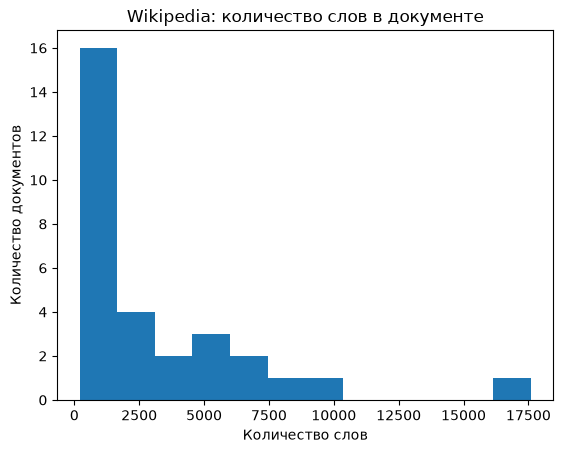

In [5]:
frame.word_count.plot.hist(bins=12, title='Wikipedia: количество слов в документе')
plt.xlabel('Количество слов')
plt.ylabel('Количество документов')
plt.show()

## 4. Существующий поиск

Примеры запросов: [neural information retrieval](https://en.wikipedia.org/w/index.php?search=neural+information+retrieval) и [python memory model](https://en.wikipedia.org/w/index.php?search=python+memory+model).

| Запрос | Наблюдение | Недостаток |
|---|---|---|
| `neural information retrieval` | Находятся энциклопедические статьи по отдельным понятиям запроса | Нет научных публикаций и практической документации в общей выдаче |
| `python memory model` | Результаты относятся к Python и управлению памятью, но прямого ответа может не быть | Узкий практический вопрос плохо соответствует названиям энциклопедических статей |

По моим наблюдениям, поиск Wikipedia лучше всего работает для известных понятий и названий статей. При полном сборе нужно также учитывать циклы и тематический дрейф в графе категорий.

## Вывод

Wikipedia подходит как один из источников корпуса: статьи содержат связный текст и полезные метаданные, а встроенный поиск позволяет сравнивать результаты будущей поисковой системы.